In [1]:
import copy
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [4]:
DATA_DIR = "./data"
QUESTION = 4
PICS_DIR = "./figures"
SEED=42
BATCH_SIZE_PRETRAIN = 256
BATCH_SIZE_SMALL = 64

EPOCHS_PRETRAIN = 10
EPOCHS_TRANSFER = 25
EPOCHS_SCRATCH = 25

LR_PRETRAIN = 1e-3
LR_TRANSFER = 1e-3
LR_SCRATCH = 1e-3

SMALL_TRAIN_SIZE = 200
SMALL_VAL_SIZE = 200      # small validation for overfitting analysis
ROT_ANGLE = 15

# LeNet

In [5]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = x.view(-1, 16 * 4 * 4)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Transforms

In [6]:
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081

transform_plain = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD)
])

# RandomRotation with same min=max applies fixed angle.
transform_rot15 = transforms.Compose([
    transforms.RandomRotation(degrees=(-ROT_ANGLE, -ROT_ANGLE)),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD)
])

# For visualization only (without normalization)
transform_rot15_vis = transforms.Compose([
    transforms.RandomRotation(degrees=(-ROT_ANGLE, -ROT_ANGLE)),
    transforms.ToTensor()
])

# Datasets

In [7]:
# Full source domain: normal MNIST
train_plain_full = datasets.MNIST(root=DATA_DIR, train=True, download=False, transform=transform_plain)
test_plain = datasets.MNIST(root=DATA_DIR, train=False, download=False, transform=transform_plain)

# Target domain: rotated MNIST
train_rot_full = datasets.MNIST(root=DATA_DIR, train=True, download=False, transform=transform_rot15)
test_rot = datasets.MNIST(root=DATA_DIR, train=False, download=False, transform=transform_rot15)

# Helper: create small rotated train/val subsets

In [ ]:
"""
Create small randomized training and validation subsets from a dataset with a fixed seed for reproducibility and return their indices.
"""
def make_small_rotated_subsets(train_dataset, train_size=200, val_size=200, seed=42):
    total_needed = train_size + val_size
    g = torch.Generator().manual_seed(seed)

    indices = torch.randperm(len(train_dataset), generator=g).tolist()
    train_idx = indices[:train_size]
    val_idx = indices[train_size:train_size + val_size]

    small_train = Subset(train_dataset, train_idx)
    small_val = Subset(train_dataset, val_idx)
    return small_train, small_val, train_idx, val_idx

In [9]:
small_rot_train, small_rot_val, small_train_idx, small_val_idx = make_small_rotated_subsets(
    train_rot_full,
    train_size=SMALL_TRAIN_SIZE,
    val_size=SMALL_VAL_SIZE,
    seed=SEED
)

# Loaders

In [10]:
train_loader_pretrain = DataLoader(train_plain_full, batch_size=BATCH_SIZE_PRETRAIN, shuffle=True, num_workers=2, pin_memory=True)
test_loader_plain = DataLoader(test_plain, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

small_train_loader = DataLoader(small_rot_train, batch_size=BATCH_SIZE_SMALL, shuffle=True, num_workers=2, pin_memory=True)
small_val_loader = DataLoader(small_rot_val, batch_size=BATCH_SIZE_SMALL, shuffle=False, num_workers=2, pin_memory=True)
test_loader_rot = DataLoader(test_rot, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

# Visualization

In [11]:
def denormalize(img_tensor, mean=MNIST_MEAN, std=MNIST_STD):
    mean = torch.tensor(mean).view(-1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1)
    return img_tensor * std + mean

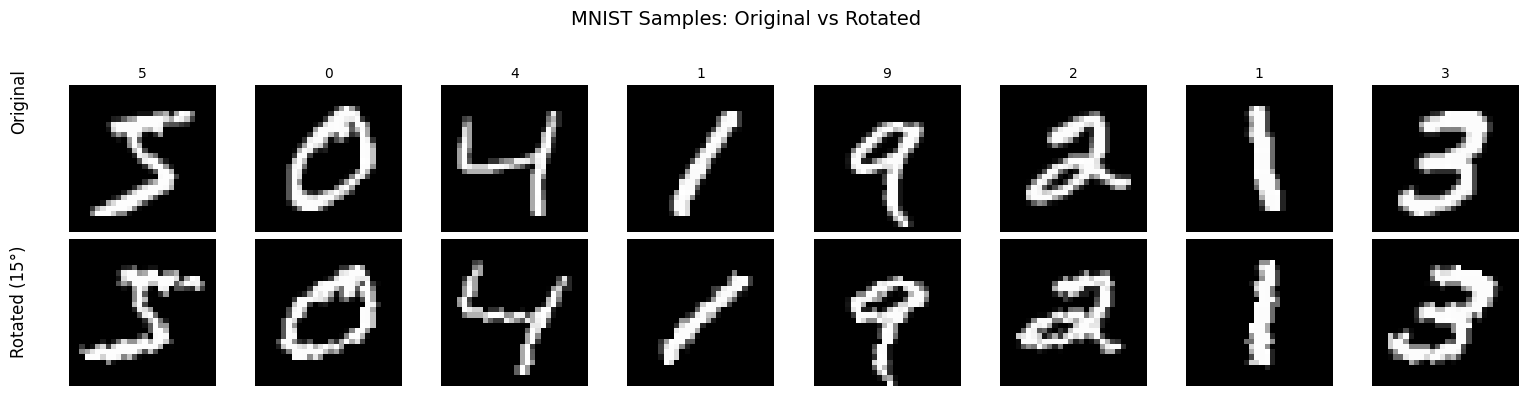

In [12]:
def show_rotated_samples(n=8):
    """
    Shows original MNIST images (top row) and their rotated versions (bottom row),
    with clearly visible row labels.
    """

    orig_ds = datasets.MNIST(
        root="./data",
        train=True,
        download=True,
        transform=transforms.ToTensor()
    )

    rot_ds = datasets.MNIST(
        root="./data",
        train=True,
        download=True,
        transform=transform_rot15_vis
    )

    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4))

    for i in range(n):
        x_orig, y = orig_ds[i]
        x_rot, _ = rot_ds[i]

        # --- top row ---
        axes[0, i].imshow(x_orig.squeeze(0), cmap="gray")
        axes[0, i].set_title(f"{y}", fontsize=10)
        axes[0, i].axis("off")

        # --- bottom row ---
        axes[1, i].imshow(x_rot.squeeze(0), cmap="gray")
        axes[1, i].axis("off")

    fig.text(0.04, 0.75, "Original", va='center', rotation=90, fontsize=12)
    fig.text(0.04, 0.25, "Rotated (15°)", va='center', rotation=90, fontsize=12)

    plt.suptitle("MNIST Samples: Original vs Rotated", fontsize=14)

    plt.tight_layout(rect=[0.06, 0, 1, 0.95])
    title = "MNIST Samples: Original vs Rotated"
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

show_rotated_samples()

In [13]:
def plot_history_no_val(history, title="Training History"):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title + " - Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title + " - Accuracy")
    plt.legend()

    plt.tight_layout()
    title = f"{title} - no val"
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [14]:
def plot_history(history, title="Training History"):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title + " - Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train Acc")
    plt.plot(epochs, history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title + " - Accuracy")
    plt.legend()

    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [15]:
def plot_confusion_matrix(cm, title="Confusion Matrix", class_names=None, figsize=(8, 6)):
    """
    Plots confusion matrix with values inside each cell.
    """
    if class_names is None:
        class_names = [str(i) for i in range(cm.shape[0])]

    plt.figure(figsize=figsize)
    plt.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.title(title)
    plt.colorbar()

    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names)
    plt.yticks(ticks, class_names)

    thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=9
            )

    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [16]:
def per_class_accuracy_from_cm(cm):
    per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)
    return per_class_acc

# Training / Evaluation

In [17]:
def compute_accuracy(logits, y):
    preds = logits.argmax(dim=1)
    return (preds == y).float().mean().item()

In [18]:
def evaluate_model(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_targets = []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)

            if criterion is not None:
                loss = criterion(logits, y)
                total_loss += loss.item() * x.size(0)

            preds = logits.argmax(dim=1)
            total_correct += (preds == y).sum().item()
            total_samples += y.size(0)

            all_preds.append(preds.cpu())
            all_targets.append(y.cpu())

    avg_loss = total_loss / total_samples if criterion is not None else None
    acc = total_correct / total_samples

    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()

    return {
        "loss": avg_loss,
        "acc": acc,
        "preds": all_preds,
        "targets": all_targets
    }

In [ ]:
"""
Train a classification model without validation, tracking training loss and accuracy.
"""
def train_model_no_val(
    model,
    train_loader,
    epochs=10,
    lr=1e-3,
    weight_decay=0.0,
    optimizer_name="adam",
    verbose=True
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    params = [p for p in model.parameters() if p.requires_grad]

    if optimizer_name.lower() == "adam":
        optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)

    history = {
        "train_loss": [],
        "train_acc": []
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_samples = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == y).sum().item()
            running_samples += y.size(0)

        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        if verbose:
            print(
                f"Epoch [{epoch+1:02d}/{epochs}] | "
                f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}"
            )

    return model, history

In [ ]:
"""
Train a classification model with validation, track performance metrics, and restore the best model based on validation accuracy.
"""
def train_model(
    model,
    train_loader,
    val_loader,
    epochs=10,
    lr=1e-3,
    weight_decay=0.0,
    optimizer_name="adam",
    verbose=True
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    params = [p for p in model.parameters() if p.requires_grad]

    if optimizer_name.lower() == "adam":
        optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_samples = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == y).sum().item()
            running_samples += y.size(0)

        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples

        val_metrics = evaluate_model(model, val_loader, criterion=criterion)
        val_loss = val_metrics["loss"]
        val_acc = val_metrics["acc"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(
                f"Epoch [{epoch+1:02d}/{epochs}] | "
                f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
                f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
            )

    model.load_state_dict(best_state)
    return model, history

# Pretrain on full plain MNIST

Pretraining LeNet on full MNIST...
Epoch [01/10] | Train Loss: 0.4658 | Train Acc: 0.8595
Epoch [02/10] | Train Loss: 0.1076 | Train Acc: 0.9677
Epoch [03/10] | Train Loss: 0.0760 | Train Acc: 0.9765
Epoch [04/10] | Train Loss: 0.0574 | Train Acc: 0.9820
Epoch [05/10] | Train Loss: 0.0484 | Train Acc: 0.9850
Epoch [06/10] | Train Loss: 0.0415 | Train Acc: 0.9867
Epoch [07/10] | Train Loss: 0.0367 | Train Acc: 0.9888
Epoch [08/10] | Train Loss: 0.0330 | Train Acc: 0.9895
Epoch [09/10] | Train Loss: 0.0282 | Train Acc: 0.9910
Epoch [10/10] | Train Loss: 0.0257 | Train Acc: 0.9919


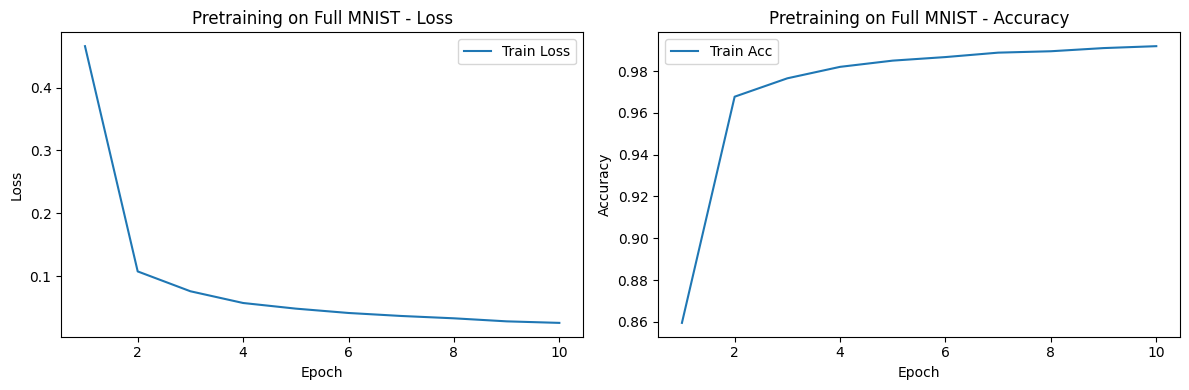

Pretrained model test accuracy on plain MNIST: 0.9881


In [21]:
pretrained_model = LeNet().to(device)

print("Pretraining LeNet on full MNIST...")
pretrained_model, pretrain_history = train_model_no_val(
    model=pretrained_model,
    train_loader=train_loader_pretrain,
    epochs=EPOCHS_PRETRAIN,
    lr=LR_PRETRAIN,
    weight_decay=0.0,
    optimizer_name="adam",
    verbose=True
)

plot_history_no_val(pretrain_history, title="Pretraining on Full MNIST")

plain_test_metrics = evaluate_model(pretrained_model, test_loader_plain, criterion=nn.CrossEntropyLoss())
print(f"Pretrained model test accuracy on plain MNIST: {plain_test_metrics['acc']:.4f}")

# Layer freezing utilities

In [22]:
def set_trainable_layers(model, mode="head_only"):
    """
    mode:
        - 'head_only'      : freeze conv1, conv2 ; train fc1, fc2, fc3
        - 'conv2_plus_head': freeze conv1 ; train conv2, fc1, fc2, fc3
        - 'full_finetune'  : all trainable
        - 'scratch'        : all trainable (new random model)
    """
    for p in model.parameters():
        p.requires_grad = False

    if mode == "head_only":
        for p in model.fc1.parameters():
            p.requires_grad = True
        for p in model.fc2.parameters():
            p.requires_grad = True
        for p in model.fc3.parameters():
            p.requires_grad = True

    elif mode == "conv2_plus_head":
        for p in model.conv2.parameters():
            p.requires_grad = True
        for p in model.fc1.parameters():
            p.requires_grad = True
        for p in model.fc2.parameters():
            p.requires_grad = True
        for p in model.fc3.parameters():
            p.requires_grad = True

    elif mode == "full_finetune":
        for p in model.parameters():
            p.requires_grad = True

    else:
        raise ValueError(f"Unknown mode: {mode}")

In [23]:
def count_trainable_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

# Experiment runners

In [24]:
def run_transfer_experiment(
    pretrained_state_dict,
    mode,
    train_loader,
    val_loader,
    test_loader,
    epochs=20,
    lr=1e-3,
    weight_decay=0.0,
    exp_name=""
):
    model = LeNet().to(device)
    model.load_state_dict(pretrained_state_dict)

    set_trainable_layers(model, mode=mode)
    total, trainable = count_trainable_params(model)

    print(f"\n===== {exp_name} =====")
    print(f"Mode: {mode}")
    print(f"Trainable params: {trainable}/{total}")

    model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        lr=lr,
        weight_decay=weight_decay,
        optimizer_name="adam",
        verbose=True
    )

    val_metrics = evaluate_model(model, val_loader, criterion=nn.CrossEntropyLoss())
    test_metrics = evaluate_model(model, test_loader, criterion=nn.CrossEntropyLoss())

    print(f"{exp_name} | Val Acc:  {val_metrics['acc']:.4f}")
    print(f"{exp_name} | Test Acc: {test_metrics['acc']:.4f}")

    return model, history, val_metrics, test_metrics

In [25]:
def run_scratch_experiment(
    train_loader,
    val_loader,
    test_loader,
    epochs=20,
    lr=1e-3,
    weight_decay=0.0,
    exp_name="Scratch"
):
    model = LeNet().to(device)

    print(f"\n===== {exp_name} =====")
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable params: {total}/{total}")

    model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        lr=lr,
        weight_decay=weight_decay,
        optimizer_name="adam",
        verbose=True
    )

    val_metrics = evaluate_model(model, val_loader, criterion=nn.CrossEntropyLoss())
    test_metrics = evaluate_model(model, test_loader, criterion=nn.CrossEntropyLoss())

    print(f"{exp_name} | Val Acc:  {val_metrics['acc']:.4f}")
    print(f"{exp_name} | Test Acc: {test_metrics['acc']:.4f}")

    return model, history, val_metrics, test_metrics

In [26]:
# Save pretrained weights
pretrained_state = copy.deepcopy(pretrained_model.state_dict())

In [27]:
# 1) Transfer: freeze conv1, conv2 and train only fc layers
model_head, hist_head, val_head, test_head = run_transfer_experiment(
    pretrained_state_dict=pretrained_state,
    mode="head_only",
    train_loader=small_train_loader,
    val_loader=small_val_loader,
    test_loader=test_loader_rot,
    epochs=EPOCHS_TRANSFER,
    lr=LR_TRANSFER,
    weight_decay=0.0,
    exp_name="Transfer - Head Only"
)


===== Transfer - Head Only =====
Mode: head_only
Trainable params: 41854/44426
Epoch [01/25] | Train Loss: 0.0784 | Train Acc: 0.9750 | Val Loss: 0.1175 | Val Acc: 0.9750
Epoch [02/25] | Train Loss: 0.0147 | Train Acc: 1.0000 | Val Loss: 0.1379 | Val Acc: 0.9750
Epoch [03/25] | Train Loss: 0.0063 | Train Acc: 1.0000 | Val Loss: 0.1613 | Val Acc: 0.9600
Epoch [04/25] | Train Loss: 0.0041 | Train Acc: 1.0000 | Val Loss: 0.1535 | Val Acc: 0.9650
Epoch [05/25] | Train Loss: 0.0023 | Train Acc: 1.0000 | Val Loss: 0.1274 | Val Acc: 0.9800
Epoch [06/25] | Train Loss: 0.0015 | Train Acc: 1.0000 | Val Loss: 0.1139 | Val Acc: 0.9850
Epoch [07/25] | Train Loss: 0.0014 | Train Acc: 1.0000 | Val Loss: 0.1081 | Val Acc: 0.9800
Epoch [08/25] | Train Loss: 0.0010 | Train Acc: 1.0000 | Val Loss: 0.1048 | Val Acc: 0.9800
Epoch [09/25] | Train Loss: 0.0007 | Train Acc: 1.0000 | Val Loss: 0.1034 | Val Acc: 0.9800
Epoch [10/25] | Train Loss: 0.0005 | Train Acc: 1.0000 | Val Loss: 0.1034 | Val Acc: 0.9800


In [28]:
# 2) Transfer: freeze conv1 only, train conv2 + fc
model_conv2, hist_conv2, val_conv2, test_conv2 = run_transfer_experiment(
    pretrained_state_dict=pretrained_state,
    mode="conv2_plus_head",
    train_loader=small_train_loader,
    val_loader=small_val_loader,
    test_loader=test_loader_rot,
    epochs=EPOCHS_TRANSFER,
    lr=LR_TRANSFER,
    weight_decay=0.0,
    exp_name="Transfer - Conv2 + Head"
)


===== Transfer - Conv2 + Head =====
Mode: conv2_plus_head
Trainable params: 44270/44426
Epoch [01/25] | Train Loss: 0.0680 | Train Acc: 0.9800 | Val Loss: 0.2054 | Val Acc: 0.9350
Epoch [02/25] | Train Loss: 0.0144 | Train Acc: 0.9950 | Val Loss: 0.1585 | Val Acc: 0.9650
Epoch [03/25] | Train Loss: 0.0051 | Train Acc: 1.0000 | Val Loss: 0.1422 | Val Acc: 0.9800
Epoch [04/25] | Train Loss: 0.0030 | Train Acc: 1.0000 | Val Loss: 0.1342 | Val Acc: 0.9800
Epoch [05/25] | Train Loss: 0.0024 | Train Acc: 1.0000 | Val Loss: 0.1309 | Val Acc: 0.9700
Epoch [06/25] | Train Loss: 0.0012 | Train Acc: 1.0000 | Val Loss: 0.1388 | Val Acc: 0.9650
Epoch [07/25] | Train Loss: 0.0007 | Train Acc: 1.0000 | Val Loss: 0.1463 | Val Acc: 0.9600
Epoch [08/25] | Train Loss: 0.0006 | Train Acc: 1.0000 | Val Loss: 0.1453 | Val Acc: 0.9600
Epoch [09/25] | Train Loss: 0.0004 | Train Acc: 1.0000 | Val Loss: 0.1395 | Val Acc: 0.9650
Epoch [10/25] | Train Loss: 0.0003 | Train Acc: 1.0000 | Val Loss: 0.1348 | Val Acc

In [29]:
# 3) Transfer: full fine-tune from pretrained
model_full, hist_full, val_full, test_full = run_transfer_experiment(
    pretrained_state_dict=pretrained_state,
    mode="full_finetune",
    train_loader=small_train_loader,
    val_loader=small_val_loader,
    test_loader=test_loader_rot,
    epochs=EPOCHS_TRANSFER,
    lr=LR_TRANSFER,
    weight_decay=0.0,
    exp_name="Transfer - Full Fine-tune"
)


===== Transfer - Full Fine-tune =====
Mode: full_finetune
Trainable params: 44426/44426


Epoch [01/25] | Train Loss: 0.0520 | Train Acc: 0.9800 | Val Loss: 0.1758 | Val Acc: 0.9500
Epoch [02/25] | Train Loss: 0.0168 | Train Acc: 1.0000 | Val Loss: 0.1794 | Val Acc: 0.9500
Epoch [03/25] | Train Loss: 0.0076 | Train Acc: 1.0000 | Val Loss: 0.1321 | Val Acc: 0.9700
Epoch [04/25] | Train Loss: 0.0031 | Train Acc: 1.0000 | Val Loss: 0.1152 | Val Acc: 0.9800
Epoch [05/25] | Train Loss: 0.0021 | Train Acc: 1.0000 | Val Loss: 0.1088 | Val Acc: 0.9800
Epoch [06/25] | Train Loss: 0.0009 | Train Acc: 1.0000 | Val Loss: 0.1074 | Val Acc: 0.9800
Epoch [07/25] | Train Loss: 0.0007 | Train Acc: 1.0000 | Val Loss: 0.1109 | Val Acc: 0.9800
Epoch [08/25] | Train Loss: 0.0005 | Train Acc: 1.0000 | Val Loss: 0.1146 | Val Acc: 0.9800
Epoch [09/25] | Train Loss: 0.0004 | Train Acc: 1.0000 | Val Loss: 0.1173 | Val Acc: 0.9800
Epoch [10/25] | Train Loss: 0.0003 | Train Acc: 1.0000 | Val Loss: 0.1187 | Val Acc: 0.9800
Epoch [11/25] | Train Loss: 0.0003 | Train Acc: 1.0000 | Val Loss: 0.1197 | Val 

In [30]:
# 4) Scratch
model_scratch, hist_scratch, val_scratch, test_scratch = run_scratch_experiment(
    train_loader=small_train_loader,
    val_loader=small_val_loader,
    test_loader=test_loader_rot,
    epochs=EPOCHS_SCRATCH,
    lr=LR_SCRATCH,
    weight_decay=0.0,
    exp_name="Scratch on 200 Rotated Samples"
)


===== Scratch on 200 Rotated Samples =====
Trainable params: 44426/44426


Epoch [01/25] | Train Loss: 2.3034 | Train Acc: 0.0800 | Val Loss: 2.2818 | Val Acc: 0.1550
Epoch [02/25] | Train Loss: 2.2520 | Train Acc: 0.2550 | Val Loss: 2.2431 | Val Acc: 0.3550
Epoch [03/25] | Train Loss: 2.1756 | Train Acc: 0.5000 | Val Loss: 2.1752 | Val Acc: 0.2600
Epoch [04/25] | Train Loss: 2.0459 | Train Acc: 0.4650 | Val Loss: 2.0683 | Val Acc: 0.2500
Epoch [05/25] | Train Loss: 1.8683 | Train Acc: 0.4500 | Val Loss: 1.9332 | Val Acc: 0.3400
Epoch [06/25] | Train Loss: 1.6473 | Train Acc: 0.5200 | Val Loss: 1.8040 | Val Acc: 0.3800
Epoch [07/25] | Train Loss: 1.4039 | Train Acc: 0.5950 | Val Loss: 1.5332 | Val Acc: 0.4250
Epoch [08/25] | Train Loss: 1.1506 | Train Acc: 0.6300 | Val Loss: 1.4137 | Val Acc: 0.4850
Epoch [09/25] | Train Loss: 0.9453 | Train Acc: 0.7750 | Val Loss: 1.1689 | Val Acc: 0.6700
Epoch [10/25] | Train Loss: 0.7285 | Train Acc: 0.8000 | Val Loss: 1.0810 | Val Acc: 0.6450
Epoch [11/25] | Train Loss: 0.6065 | Train Acc: 0.7850 | Val Loss: 0.9509 | Val 

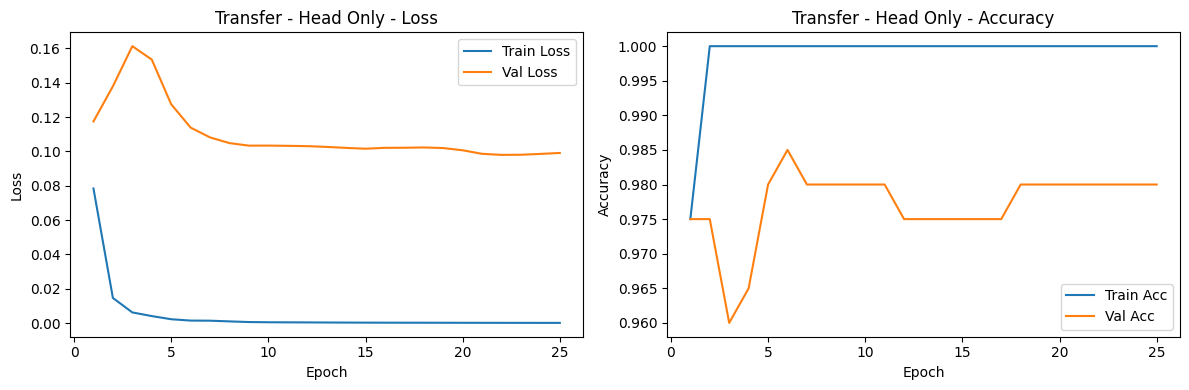

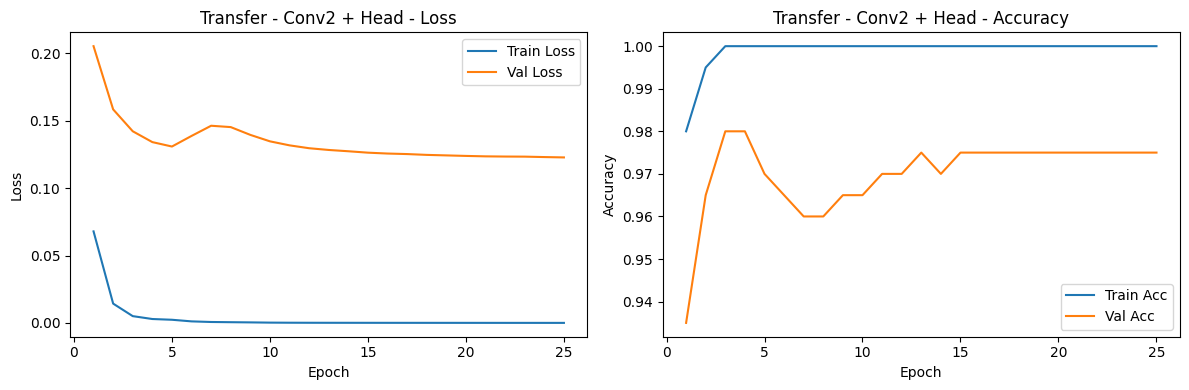

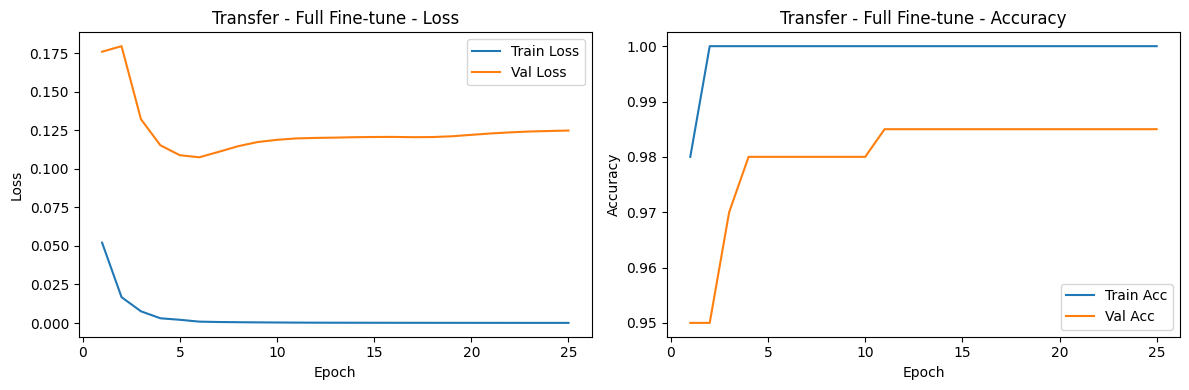

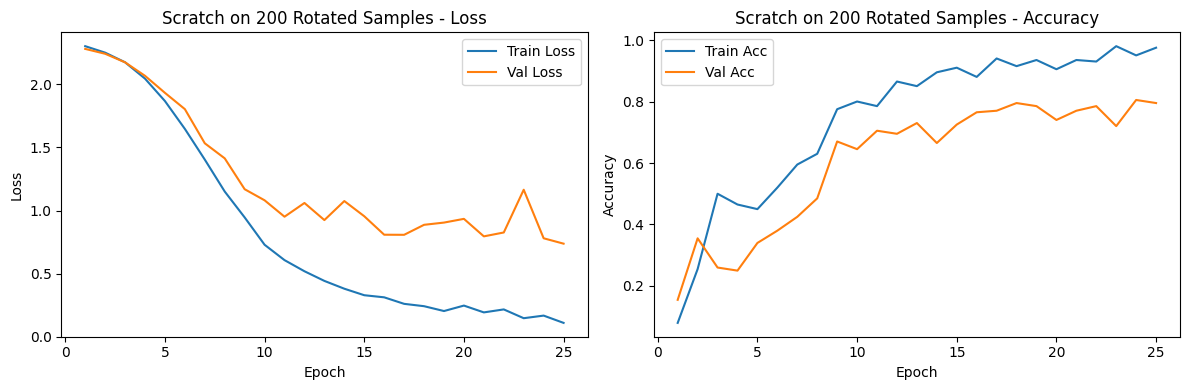

In [31]:
plot_history(hist_head, title="Transfer - Head Only")
plot_history(hist_conv2, title="Transfer - Conv2 + Head")
plot_history(hist_full, title="Transfer - Full Fine-tune")
plot_history(hist_scratch, title="Scratch on 200 Rotated Samples")

# Summary table

In [32]:
summary_df = pd.DataFrame([
    {
        "Experiment": "Transfer - Head Only",
        "Val Acc": val_head["acc"],
        "Test Acc (Rot15)": test_head["acc"],
        "Final Train Acc": hist_head["train_acc"][-1],
        "Final Val Acc": hist_head["val_acc"][-1],
        "Final Train Loss": hist_head["train_loss"][-1],
        "Final Val Loss": hist_head["val_loss"][-1],
    },
    {
        "Experiment": "Transfer - Conv2 + Head",
        "Val Acc": val_conv2["acc"],
        "Test Acc (Rot15)": test_conv2["acc"],
        "Final Train Acc": hist_conv2["train_acc"][-1],
        "Final Val Acc": hist_conv2["val_acc"][-1],
        "Final Train Loss": hist_conv2["train_loss"][-1],
        "Final Val Loss": hist_conv2["val_loss"][-1],
    },
    {
        "Experiment": "Transfer - Full Fine-tune",
        "Val Acc": val_full["acc"],
        "Test Acc (Rot15)": test_full["acc"],
        "Final Train Acc": hist_full["train_acc"][-1],
        "Final Val Acc": hist_full["val_acc"][-1],
        "Final Train Loss": hist_full["train_loss"][-1],
        "Final Val Loss": hist_full["val_loss"][-1],
    },
    {
        "Experiment": "Scratch",
        "Val Acc": val_scratch["acc"],
        "Test Acc (Rot15)": test_scratch["acc"],
        "Final Train Acc": hist_scratch["train_acc"][-1],
        "Final Val Acc": hist_scratch["val_acc"][-1],
        "Final Train Loss": hist_scratch["train_loss"][-1],
        "Final Val Loss": hist_scratch["val_loss"][-1],
    },
])

summary_df

,Experiment,Val Acc,Test Acc (Rot15),Final Train Acc,Final Val Acc,Final Train Loss,Final Val Loss
0,Transfer - Head Only,0.985,0.9564,1.000,0.980,0.000165,0.099096
1,Transfer - Conv2 + Head,0.980,0.9527,1.000,0.975,0.000080,0.122827
2,Transfer - Full Fine-tune,0.985,0.9610,1.000,0.985,0.000090,0.124759
3,Scratch,0.805,0.8023,0.975,0.795,0.108821,0.737066


# Confusion matrices + per-class accuracy

In [33]:
def evaluate_and_plot_cm(model, loader, title_prefix=""):
    metrics = evaluate_model(model, loader, criterion=nn.CrossEntropyLoss())
    cm = confusion_matrix(metrics["targets"], metrics["preds"])
    per_class_acc = per_class_accuracy_from_cm(cm)

    print(f"\n{title_prefix} - Overall Accuracy: {metrics['acc']:.4f}")
    print("Per-class accuracy:")
    for i, acc in enumerate(per_class_acc):
        print(f"Class {i}: {acc:.4f}")

    plot_confusion_matrix(cm, title=f"{title_prefix} - Confusion Matrix")
    return cm, per_class_acc


Transfer - Head Only - Overall Accuracy: 0.9564
Per-class accuracy:
Class 0: 0.9949
Class 1: 0.9974
Class 2: 0.9438
Class 3: 0.9723
Class 4: 0.9308
Class 5: 0.8957
Class 6: 0.9916
Class 7: 0.9523
Class 8: 0.9199
Class 9: 0.9544


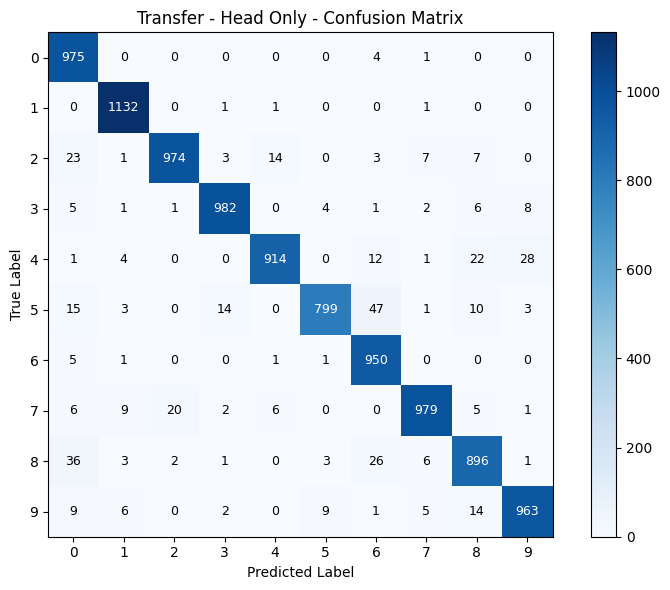


Transfer - Conv2 + Head - Overall Accuracy: 0.9527
Per-class accuracy:
Class 0: 0.9959
Class 1: 0.9991
Class 2: 0.9399
Class 3: 0.9782
Class 4: 0.9562
Class 5: 0.8991
Class 6: 0.9875
Class 7: 0.9475
Class 8: 0.8758
Class 9: 0.9366


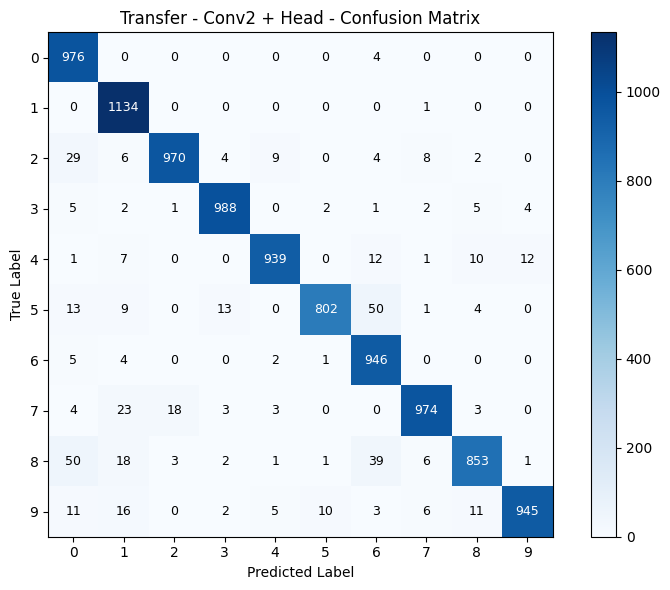


Transfer - Full Fine-tune - Overall Accuracy: 0.9610
Per-class accuracy:
Class 0: 0.9939
Class 1: 0.9921
Class 2: 0.9651
Class 3: 0.9832
Class 4: 0.9236
Class 5: 0.9092
Class 6: 0.9854
Class 7: 0.9397
Class 8: 0.9415
Class 9: 0.9673


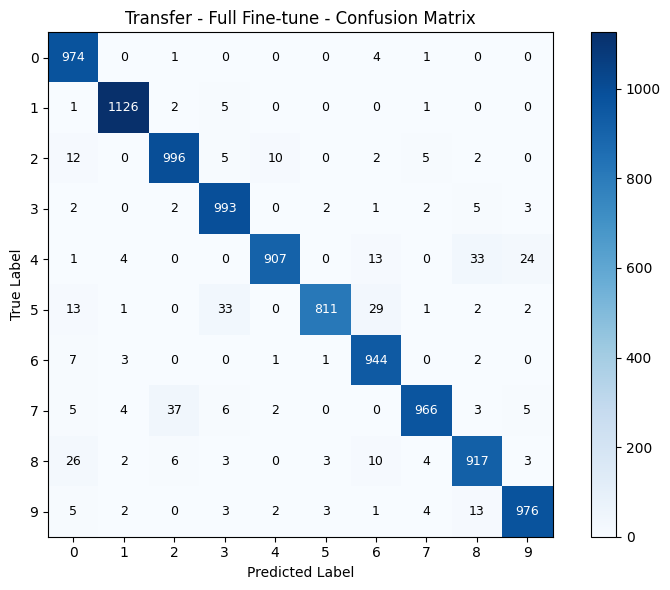


Scratch - Overall Accuracy: 0.8023
Per-class accuracy:
Class 0: 0.9571
Class 1: 0.9656
Class 2: 0.8983
Class 3: 0.7248
Class 4: 0.7485
Class 5: 0.5762
Class 6: 0.8528
Class 7: 0.8016
Class 8: 0.6242
Class 9: 0.8246


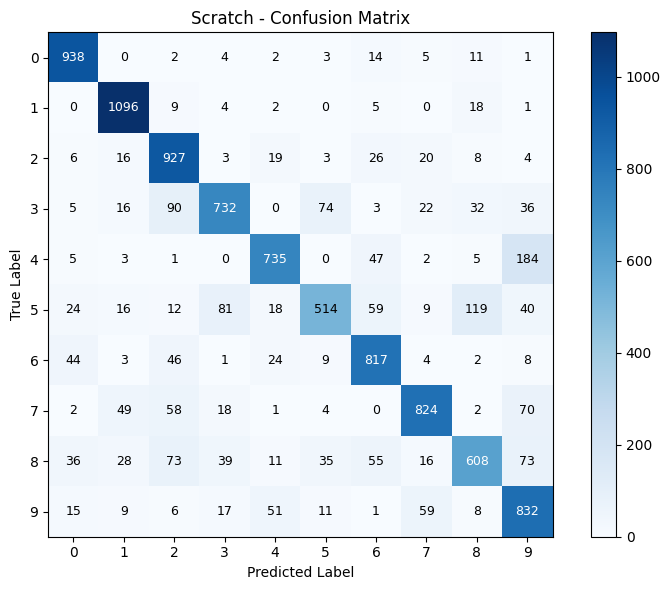

In [34]:
cm_head, pca_head = evaluate_and_plot_cm(model_head, test_loader_rot, "Transfer - Head Only")
cm_conv2, pca_conv2 = evaluate_and_plot_cm(model_conv2, test_loader_rot, "Transfer - Conv2 + Head")
cm_full, pca_full = evaluate_and_plot_cm(model_full, test_loader_rot, "Transfer - Full Fine-tune")
cm_scratch, pca_scratch = evaluate_and_plot_cm(model_scratch, test_loader_rot, "Scratch")

# Transferability analysis

In [35]:
def generalization_gap(history):
    return history["train_acc"][-1] - history["val_acc"][-1]

In [36]:
transferability_df = pd.DataFrame([
    {
        "Setting": "Head Only",
        "Trainable Layers": "fc1, fc2, fc3",
        "Rot15 Test Acc": test_head["acc"],
        "Val Acc": val_head["acc"],
        "Generalization Gap": generalization_gap(hist_head)
    },
    {
        "Setting": "Conv2 + Head",
        "Trainable Layers": "conv2, fc1, fc2, fc3",
        "Rot15 Test Acc": test_conv2["acc"],
        "Val Acc": val_conv2["acc"],
        "Generalization Gap": generalization_gap(hist_conv2)
    },
    {
        "Setting": "Full Fine-tune",
        "Trainable Layers": "all layers",
        "Rot15 Test Acc": test_full["acc"],
        "Val Acc": val_full["acc"],
        "Generalization Gap": generalization_gap(hist_full)
    },
    {
        "Setting": "Scratch",
        "Trainable Layers": "all layers from random init",
        "Rot15 Test Acc": test_scratch["acc"],
        "Val Acc": val_scratch["acc"],
        "Generalization Gap": generalization_gap(hist_scratch)
    },
])

transferability_df

,Setting,Trainable Layers,Rot15 Test Acc,Val Acc,Generalization Gap
0,Head Only,"fc1, fc2, fc3",0.9564,0.985,0.020
1,Conv2 + Head,"conv2, fc1, fc2, fc3",0.9527,0.980,0.025
2,Full Fine-tune,all layers,0.9610,0.985,0.015
3,Scratch,all layers from random init,0.8023,0.805,0.180


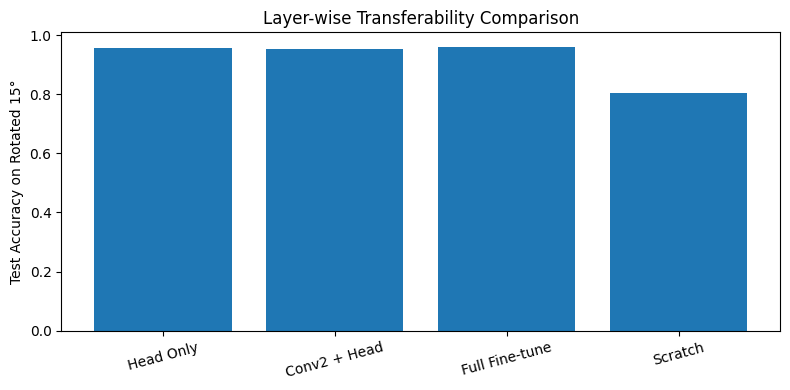

In [37]:
plt.figure(figsize=(8, 4))
plt.bar(
    transferability_df["Setting"],
    transferability_df["Rot15 Test Acc"]
)
plt.ylabel("Test Accuracy on Rotated 15°")
plt.title("Layer-wise Transferability Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
title = "Layer-wise Transferability Comparison"
filename = f"{QUESTION}_{title}.png"
save_path = os.path.join(PICS_DIR, filename)
plt.savefig(save_path, dpi=300)
plt.show()

In [ ]:
def print_transferability_interpretation():
    results = {
        "Head Only": test_head["acc"],
        "Conv2 + Head": test_conv2["acc"],
        "Full Fine-tune": test_full["acc"],
        "Scratch": test_scratch["acc"],
    }

    sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)

    print("\n===== Preliminary Interpretation =====")
    print("Ranking by Rot15 test accuracy:")
    for name, score in sorted_results:
        print(f"{name}: {score:.4f}")


print_transferability_interpretation()


===== Preliminary Interpretation =====
Ranking by Rot15 test accuracy:
Full Fine-tune: 0.9610
Head Only: 0.9564
Conv2 + Head: 0.9527
Scratch: 0.8023


In [75]:
class SmallDomainCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x).squeeze(1)
        return x

In [76]:
from torch.utils.data import Dataset

In [77]:
class RawImageDomainDataset(Dataset):
    def __init__(self, source_dataset, target_dataset, source_indices):
        self.source_dataset = source_dataset
        self.target_dataset = target_dataset
        self.source_indices = source_indices

        self.n_source = len(source_indices)
        self.n_target = len(target_dataset)

    def __len__(self):
        return self.n_source + self.n_target

    def __getitem__(self, idx):
        if idx < self.n_source:
            x, _ = self.source_dataset[self.source_indices[idx]]
            d = 1.0
        else:
            x, _ = self.target_dataset[idx - self.n_source]
            d = 0.0

        return x, torch.tensor(d, dtype=torch.float32)

In [78]:
def train_domain_classifier(model, loader, epochs=5):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for x, d in loader:
            x, d = x.to(device), d.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, d)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Domain Clf Epoch {epoch+1}: loss={total_loss:.4f}")

In [79]:
@torch.no_grad()
def estimate_weights(model, source_subset):
    model.eval()
    loader = DataLoader(source_subset, batch_size=256)

    weights = []

    for x, _ in loader:
        x = x.to(device)
        logits = model(x)
        c = torch.sigmoid(logits).clamp(1e-4, 1 - 1e-4)

        w = (1 - c) / c
        w = torch.clamp(w, 0.0, 5.0)

        weights.extend(w.cpu().numpy())

    return np.array(weights, dtype=np.float32)

In [80]:
class WeightedDataset(Dataset):
    def __init__(self, base_dataset, weights):
        self.base = base_dataset
        self.weights = weights

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        x, y = self.base[idx]
        w = self.weights[idx]
        return x, y, torch.tensor(w, dtype=torch.float32)

In [81]:
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

In [82]:
transform_plain = transforms.ToTensor()

transform_rot = transforms.Compose([
    transforms.RandomRotation((15, 15)),
    transforms.ToTensor()
])

train_plain = datasets.MNIST("./data", train=True, download=False, transform=transform_plain)
test_rot = datasets.MNIST("./data", train=False, download=False, transform=transform_rot)

test_loader_rot = DataLoader(test_rot, batch_size=256)

# 200 target samples
indices = np.random.choice(len(train_plain), size=200, replace=False)
target_200 = Subset(
    datasets.MNIST("./data", train=True, download=False, transform=transform_rot),
    indices
)


In [ ]:
def run():
    print("\n=== Reweighting with 200 samples ===")

    # sample 200 source
    source_indices = np.random.choice(len(train_plain), size=200, replace=False)
    source_subset = Subset(train_plain, source_indices)

    # domain dataset
    domain_ds = RawImageDomainDataset(train_plain, target_200, source_indices)
    domain_loader = DataLoader(domain_ds, batch_size=128, shuffle=True)

    # domain clf
    domain_model = SmallDomainCNN()
    train_domain_classifier(domain_model, domain_loader)

    # weights
    weights = estimate_weights(domain_model, source_subset)
    weighted_ds = WeightedDataset(source_subset, weights)
    weighted_loader = DataLoader(weighted_ds, batch_size=128, shuffle=True)

    # train model
    model = LeNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(8):
        model.train()
        total_loss = 0

        for x, y, w in weighted_loader:
            x, y, w = x.to(device), y.to(device), w.to(device)

            optimizer.zero_grad()
            logits = model(x)

            loss = (F.cross_entropy(logits, y, reduction="none") * w).mean()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1} loss={total_loss:.4f}")

    acc = evaluate(model, test_loader_rot)
    print(f"\nFinal Rot15 Test Accuracy: {acc:.4f}")
    
run()


=== Reweighting with 200 samples ===
Domain Clf Epoch 1: loss=2.7723
Domain Clf Epoch 2: loss=2.6933
Domain Clf Epoch 3: loss=2.7928
Domain Clf Epoch 4: loss=2.5573
Domain Clf Epoch 5: loss=2.5433
Epoch 1 loss=3.7557
Epoch 2 loss=3.7240
Epoch 3 loss=3.7727
Epoch 4 loss=3.7126
Epoch 5 loss=3.6588
Epoch 6 loss=3.6471
Epoch 7 loss=3.6567
Epoch 8 loss=3.6072

Final Rot15 Test Accuracy: 0.3198
